<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG9_Klasifikasi_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Praktikum 1

### Langah 1 - Load Data

In [1]:
import pandas as pd
data = pd.read_csv('iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Langkah 2 - Eksplorasi Data

In [3]:
data.info()
data.describe()
data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


### Langkah 3 - Visualisasi Data

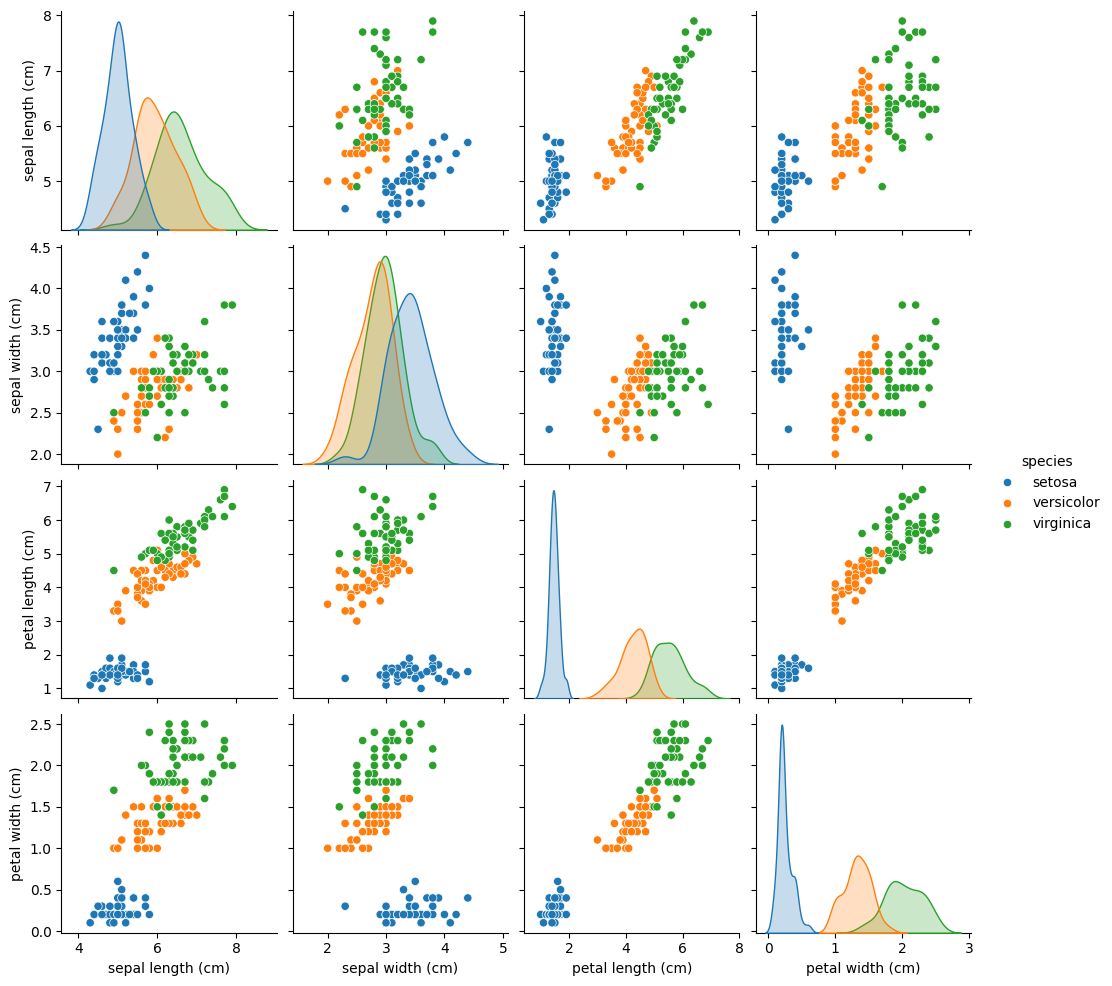

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

### Langkah 4 - Preprocessing

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Langkah 5 - Buat Model kNN

In [7]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

### Langkah 6 - Evaluasi Model kNN

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



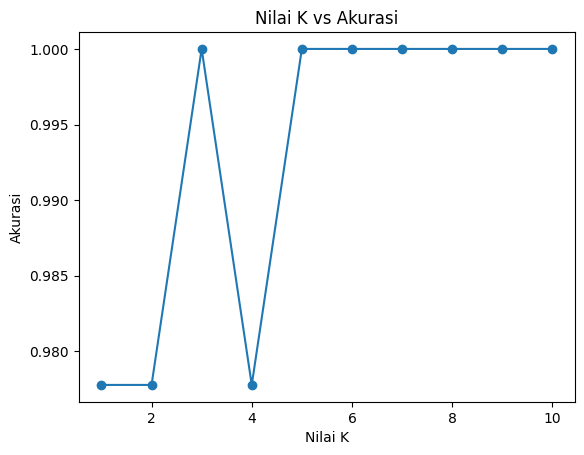

In [11]:
	acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

## Praktikum 2

### Langkah 1 - Buat Dataset Dummy

In [28]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
X, y = make_classification(n_samples=30, n_features=2, n_classes=2,
                           n_informative=2, n_redundant=0, n_repeated=0,
                           shuffle=False, random_state=2092)

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[209  98]
 [ 65  35]
 [132 133]
 [139 119]
 [199 141]
 [ 78  73]
 [ 89  92]
 [150 146]
 [124 227]
 [166 211]
 [ 62  41]
 [115 202]
 [ 66  27]
 [ 79  53]
 [122   3]
 [  3 256]
 [ 84 125]
 [ 84 122]
 [305  71]
 [213  19]
 [ 24 134]
 [ 23 175]
 [ 92 196]
 [ 81  90]
 [ 54 103]
 [ 75 107]
 [ 93  89]
 [  1 111]
 [ 31 110]
 [ 83 119]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


### Langkah 2 (Opsional) - Membuat Data Frame

In [29]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,209,98,0
1,65,35,0
2,132,133,0
3,139,119,0
4,199,141,0


### Langkah 3 (Opsional) - Labeling

In [30]:
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,209,98,Kelas B
1,65,35,Kelas B
2,132,133,Kelas B
3,139,119,Kelas B
4,199,141,Kelas B


### Langkah 4 - Visualisasi Data

/tmp/ipykernel_3033/2947333296.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_3033/2947333296.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


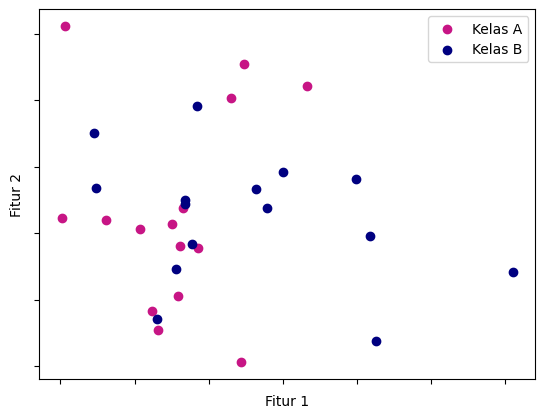

In [31]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

### Langkah 5 - Model Multinomial Naive Bayes

In [32]:
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6190476190476191
Hasil akurasi data test: 0.7777777777777778


### Langkah 6 - Model Gaussian Naive Bayes

In [33]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6666666666666666
Hasil akurasi data test (Gaussian): 0.5555555555555556


## Praktikum 3

### Langkah 1 - Load Data

In [38]:
import numpy as np
import pandas as pd
df = pd.read_csv('spam.csv', encoding='latin-1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


### Langkah 2 - Preprocessing

#### Langkah 2a - Drop Kolom

In [39]:
df = df.drop(df.iloc[:, 2:], axis=1)
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# Cek data
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


#### Langkah 2b - Inspeksi Data

In [40]:
	# Cek Jumlah Data Per Kelas
	print(df['Labels'].value_counts())
	print('\n')

	# Cek Kelengkapan Data
	print(df.info())
	print('\n')

	# Cek Statistik Deskriptif
	print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


#### Langkah 2c - Encoding Label

In [41]:
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


#### Langkah 2d - Pisahkan Fitur dengan Label

In [43]:
X = df['SMS'].values
y = df['Labels'].values

### Langkah 3 - Ekstraksi Fitur

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test (hanya transform, tidak fit, untuk mencegah data leakage)
X_test = bow.transform(X_test)

In [47]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


### Langkah 4 - Training dan Evaluasi Model

In [49]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## Tugas 1

### Load data dan split

In [64]:
df = pd.read_csv('voice.csv')

print(df.shape)
print(df['label'].value_counts())
print('Missing value:', df.isnull().sum().sum())

df['label'] = df['label'].map({'male': 1, 'female': 0})

X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

(3168, 21)
label
male      1584
female    1584
Name: count, dtype: int64
Missing value: 0


### 1. Model kNN baseline

In [65]:
def make_knn(k=5):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

base = make_knn(5)
base.fit(X_train, y_train)
print('Baseline (semua fitur, k=5)')
print('Akurasi train:', accuracy_score(y_train, base.predict(X_train)))
print('Akurasi test :', accuracy_score(y_test, base.predict(X_test)))
print('CV mean      :', cross_val_score(make_knn(5), X_train, y_train, cv=cv).mean())

Baseline (semua fitur, k=5)
Akurasi train: 0.9830307813733228
Akurasi test : 0.9763406940063092
CV mean      : 0.9696088749600456


### 2. Percobaan seleksi fitur

meanfun     0.555423
IQR         0.449243
Q25         0.406964
sd          0.302449
mode        0.177453
sp.ent      0.170729
sfm         0.126971
meanfreq    0.116538
centroid    0.116538
mindom      0.095199
maxdom      0.086317
median      0.081538
skew        0.078524
dfrange     0.077959
meandom     0.056094
kurt        0.041118
maxfun      0.039337
minfun      0.037730
modindx     0.008971
Q75         0.000000
dtype: float64


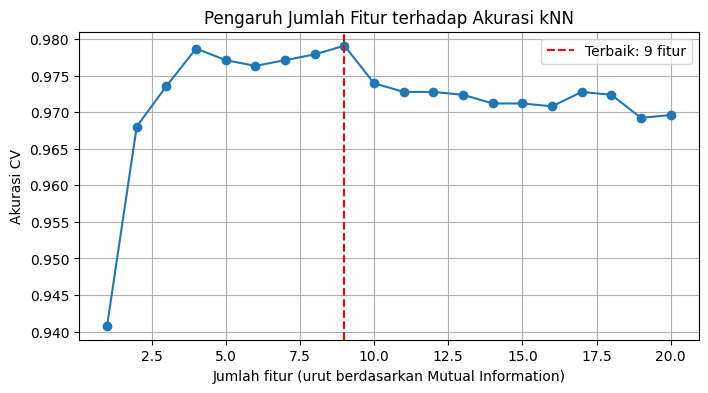

Top-9 fitur MI: ['meanfun', 'IQR', 'Q25', 'sd', 'mode', 'sp.ent', 'sfm', 'meanfreq', 'centroid'] | CV = 0.979081008177998
Fitur hasil Forward Selection: ['IQR', 'sfm', 'mode', 'meanfun'] | CV = 0.9806628154454241
            Skenario  Jumlah fitur  Akurasi CV
2  Forward Selection             4    0.980663
1  Top-9 Mutual Info             9    0.979081
0        Semua fitur            20    0.969609


In [66]:
mi = mutual_info_classif(X_train, y_train, random_state=42)
mi_rank = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(mi_rank)

n_range = range(1, len(X.columns) + 1)
scores_n = []
for n in n_range:
    cols = mi_rank.index[:n]
    s = cross_val_score(make_knn(5), X_train[cols], y_train, cv=cv).mean()
    scores_n.append(s)

best_n = n_range[int(np.argmax(scores_n))]
cols_mi = list(mi_rank.index[:best_n])

plt.figure(figsize=(8, 4))
plt.plot(list(n_range), scores_n, marker='o')
plt.axvline(best_n, color='r', linestyle='--', label=f'Terbaik: {best_n} fitur')
plt.xlabel('Jumlah fitur (urut berdasarkan Mutual Information)')
plt.ylabel('Akurasi CV')
plt.title('Pengaruh Jumlah Fitur terhadap Akurasi kNN')
plt.legend()
plt.grid(True)
plt.show()
print(f'Top-{best_n} fitur MI:', cols_mi, '| CV =', max(scores_n))

sfs = SequentialFeatureSelector(
    make_knn(5), n_features_to_select='auto', tol=0.001,
    direction='forward', scoring='accuracy', cv=cv, n_jobs=-1)
sfs.fit(X_train, y_train)
cols_sfs = list(X.columns[sfs.get_support()])
cv_sfs = cross_val_score(make_knn(5), X_train[cols_sfs], y_train, cv=cv).mean()
print('Fitur hasil Forward Selection:', cols_sfs, '| CV =', cv_sfs)

cols_all = list(X.columns)
cv_all = cross_val_score(make_knn(5), X_train[cols_all], y_train, cv=cv).mean()

hasil = pd.DataFrame({
    'Skenario': ['Semua fitur', f'Top-{best_n} Mutual Info', 'Forward Selection'],
    'Jumlah fitur': [len(cols_all), len(cols_mi), len(cols_sfs)],
    'Akurasi CV': [cv_all, max(scores_n), cv_sfs]
})
print(hasil.sort_values('Akurasi CV', ascending=False))

In [67]:
kandidat = {
    'Semua fitur': (cols_all, cv_all),
    f'Top-{best_n} Mutual Info': (cols_mi, max(scores_n)),
    'Forward Selection': (cols_sfs, cv_sfs),
}
nama_terbaik = max(kandidat, key=lambda n: kandidat[n][1])
selected = kandidat[nama_terbaik][0]

print('Skenario terbaik :', nama_terbaik)
print('Fitur terpilih   :', selected)
print('Akurasi CV       :', kandidat[nama_terbaik][1])

Skenario terbaik : Forward Selection
Fitur terpilih   : ['IQR', 'sfm', 'mode', 'meanfun']
Akurasi CV       : 0.9806628154454241


### 3. Mencari nilai k terbaik dengan fitur terpilih

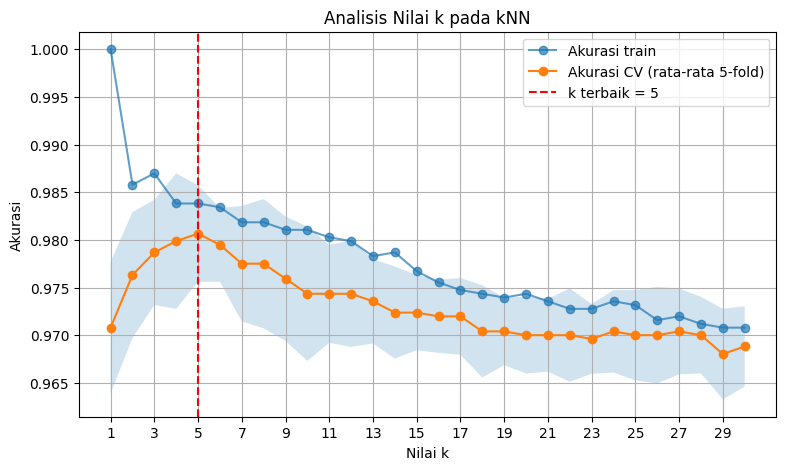

k terbaik: 5 | Akurasi CV: 0.9807


In [68]:
k_range = range(1, 31)
cv_mean, cv_std, train_acc = [], [], []

for k in k_range:
    sk = cross_val_score(make_knn(k), X_train[selected], y_train, cv=cv)
    cv_mean.append(sk.mean())
    cv_std.append(sk.std())
    m = make_knn(k).fit(X_train[selected], y_train)
    train_acc.append(accuracy_score(y_train, m.predict(X_train[selected])))

cv_mean = np.array(cv_mean)
cv_std = np.array(cv_std)
best_k = list(k_range)[int(np.argmax(cv_mean))]

plt.figure(figsize=(9, 5))
plt.plot(k_range, train_acc, marker='o', label='Akurasi train', alpha=0.7)
plt.plot(k_range, cv_mean, marker='o', label='Akurasi CV (rata-rata 5-fold)')
plt.fill_between(k_range, cv_mean - cv_std, cv_mean + cv_std, alpha=0.2)
plt.axvline(best_k, color='r', linestyle='--', label=f'k terbaik = {best_k}')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.title('Analisis Nilai k pada kNN')
plt.xticks(range(1, 31, 2))
plt.legend()
plt.grid(True)
plt.show()

print(f'k terbaik: {best_k} | Akurasi CV: {cv_mean.max():.4f}')

### Evaluasi akhir pada data test

Fitur : ['IQR', 'sfm', 'mode', 'meanfun']
k     : 5
Akurasi train: 0.983820047355959
Akurasi test : 0.9889589905362776
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



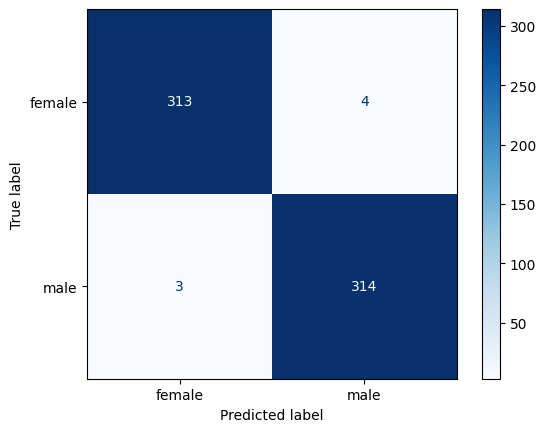

In [69]:
final = make_knn(best_k)
final.fit(X_train[selected], y_train)
y_pred = final.predict(X_test[selected])

print(f'Fitur : {selected}')
print(f'k     : {best_k}')
print('Akurasi train:', accuracy_score(y_train, final.predict(X_train[selected])))
print('Akurasi test :', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['female', 'male']).plot(cmap='Blues')
plt.show()

## Tugas 2

### Import & load data

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

df = pd.read_csv('spam.csv', encoding='latin-1')

# Ambil hanya 2 kolom yang dipakai (3 kolom lain kosong)
df = df[['v1', 'v2']]
df.columns = ['label', 'text']

print(df.shape)
print(df['label'].value_counts())
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Split data

In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'],
    test_size=0.2, random_state=42, stratify=df['label']
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (4457,) | Test: (1115,)


### Model 1, Multinomial NB + CountVectorizer (stop_words aktif)

CountVectorizer + MultinomialNB
Jumlah fitur: 7440
Accuracy : 0.9838565022421525
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



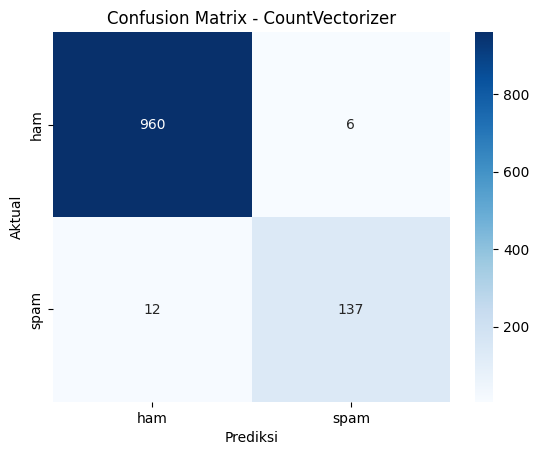

In [73]:
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

nb_cv = MultinomialNB()
nb_cv.fit(X_train_cv, y_train)
y_pred_cv = nb_cv.predict(X_test_cv)

print("CountVectorizer + MultinomialNB")
print("Jumlah fitur:", X_train_cv.shape[1])
print("Accuracy :", accuracy_score(y_test, y_pred_cv))
print(classification_report(y_test, y_pred_cv))

cm_cv = confusion_matrix(y_test, y_pred_cv, labels=['ham', 'spam'])
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - CountVectorizer')
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

### Model 2, Multinomial NB + TF-IDF (stop_words aktif)

TF-IDF + MultinomialNB
Jumlah fitur: 7440
Accuracy : 0.968609865470852
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



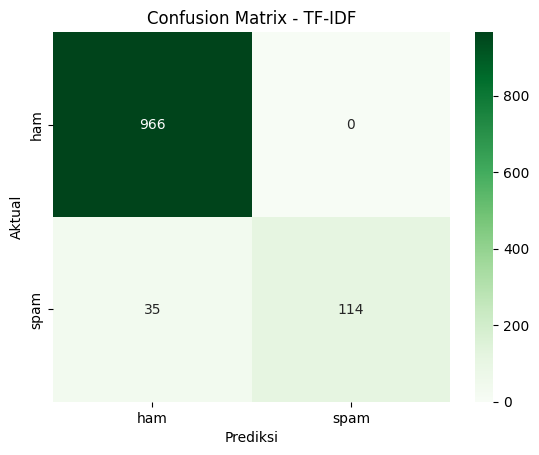

In [74]:
tfidf = TfidfVectorizer(stop_words='english')
X_train_tf = tfidf.fit_transform(X_train)
X_test_tf = tfidf.transform(X_test)

nb_tf = MultinomialNB()
nb_tf.fit(X_train_tf, y_train)
y_pred_tf = nb_tf.predict(X_test_tf)

print("TF-IDF + MultinomialNB")
print("Jumlah fitur:", X_train_tf.shape[1])
print("Accuracy :", accuracy_score(y_test, y_pred_tf))
print(classification_report(y_test, y_pred_tf))

cm_tf = confusion_matrix(y_test, y_pred_tf, labels=['ham', 'spam'])
sns.heatmap(cm_tf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.title('Confusion Matrix - TF-IDF')
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.show()

### Perbandingan

In [75]:
hasil = pd.DataFrame({
    'Fitur': ['CountVectorizer', 'TF-IDF'],
    'Accuracy':  [accuracy_score(y_test, y_pred_cv),
                  accuracy_score(y_test, y_pred_tf)],
    'Precision (spam)': [precision_score(y_test, y_pred_cv, pos_label='spam'),
                         precision_score(y_test, y_pred_tf, pos_label='spam')],
    'Recall (spam)':    [recall_score(y_test, y_pred_cv, pos_label='spam'),
                         recall_score(y_test, y_pred_tf, pos_label='spam')],
    'F1 (spam)':        [f1_score(y_test, y_pred_cv, pos_label='spam'),
                         f1_score(y_test, y_pred_tf, pos_label='spam')],
})
hasil

,Fitur,Accuracy,Precision (spam),Recall (spam),F1 (spam)
0,CountVectorizer,0.983857,0.958042,0.919463,0.938356
1,TF-IDF,0.968610,1.000000,0.765101,0.866920
